=== Task 1: Downloading & Loading Dataset ===
Download completed.

Dataset successfully loaded!
Number of rows: 45211
Number of columns: 17

--- First 5 rows ---
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may  

/tmp/ipykernel_781/3091978484.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0, 0], x='y', data=df, palette='Set2')
/tmp/ipykernel_781/3091978484.py:143: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[4, 0], x='y', y='balance', data=df, palette='Set2')


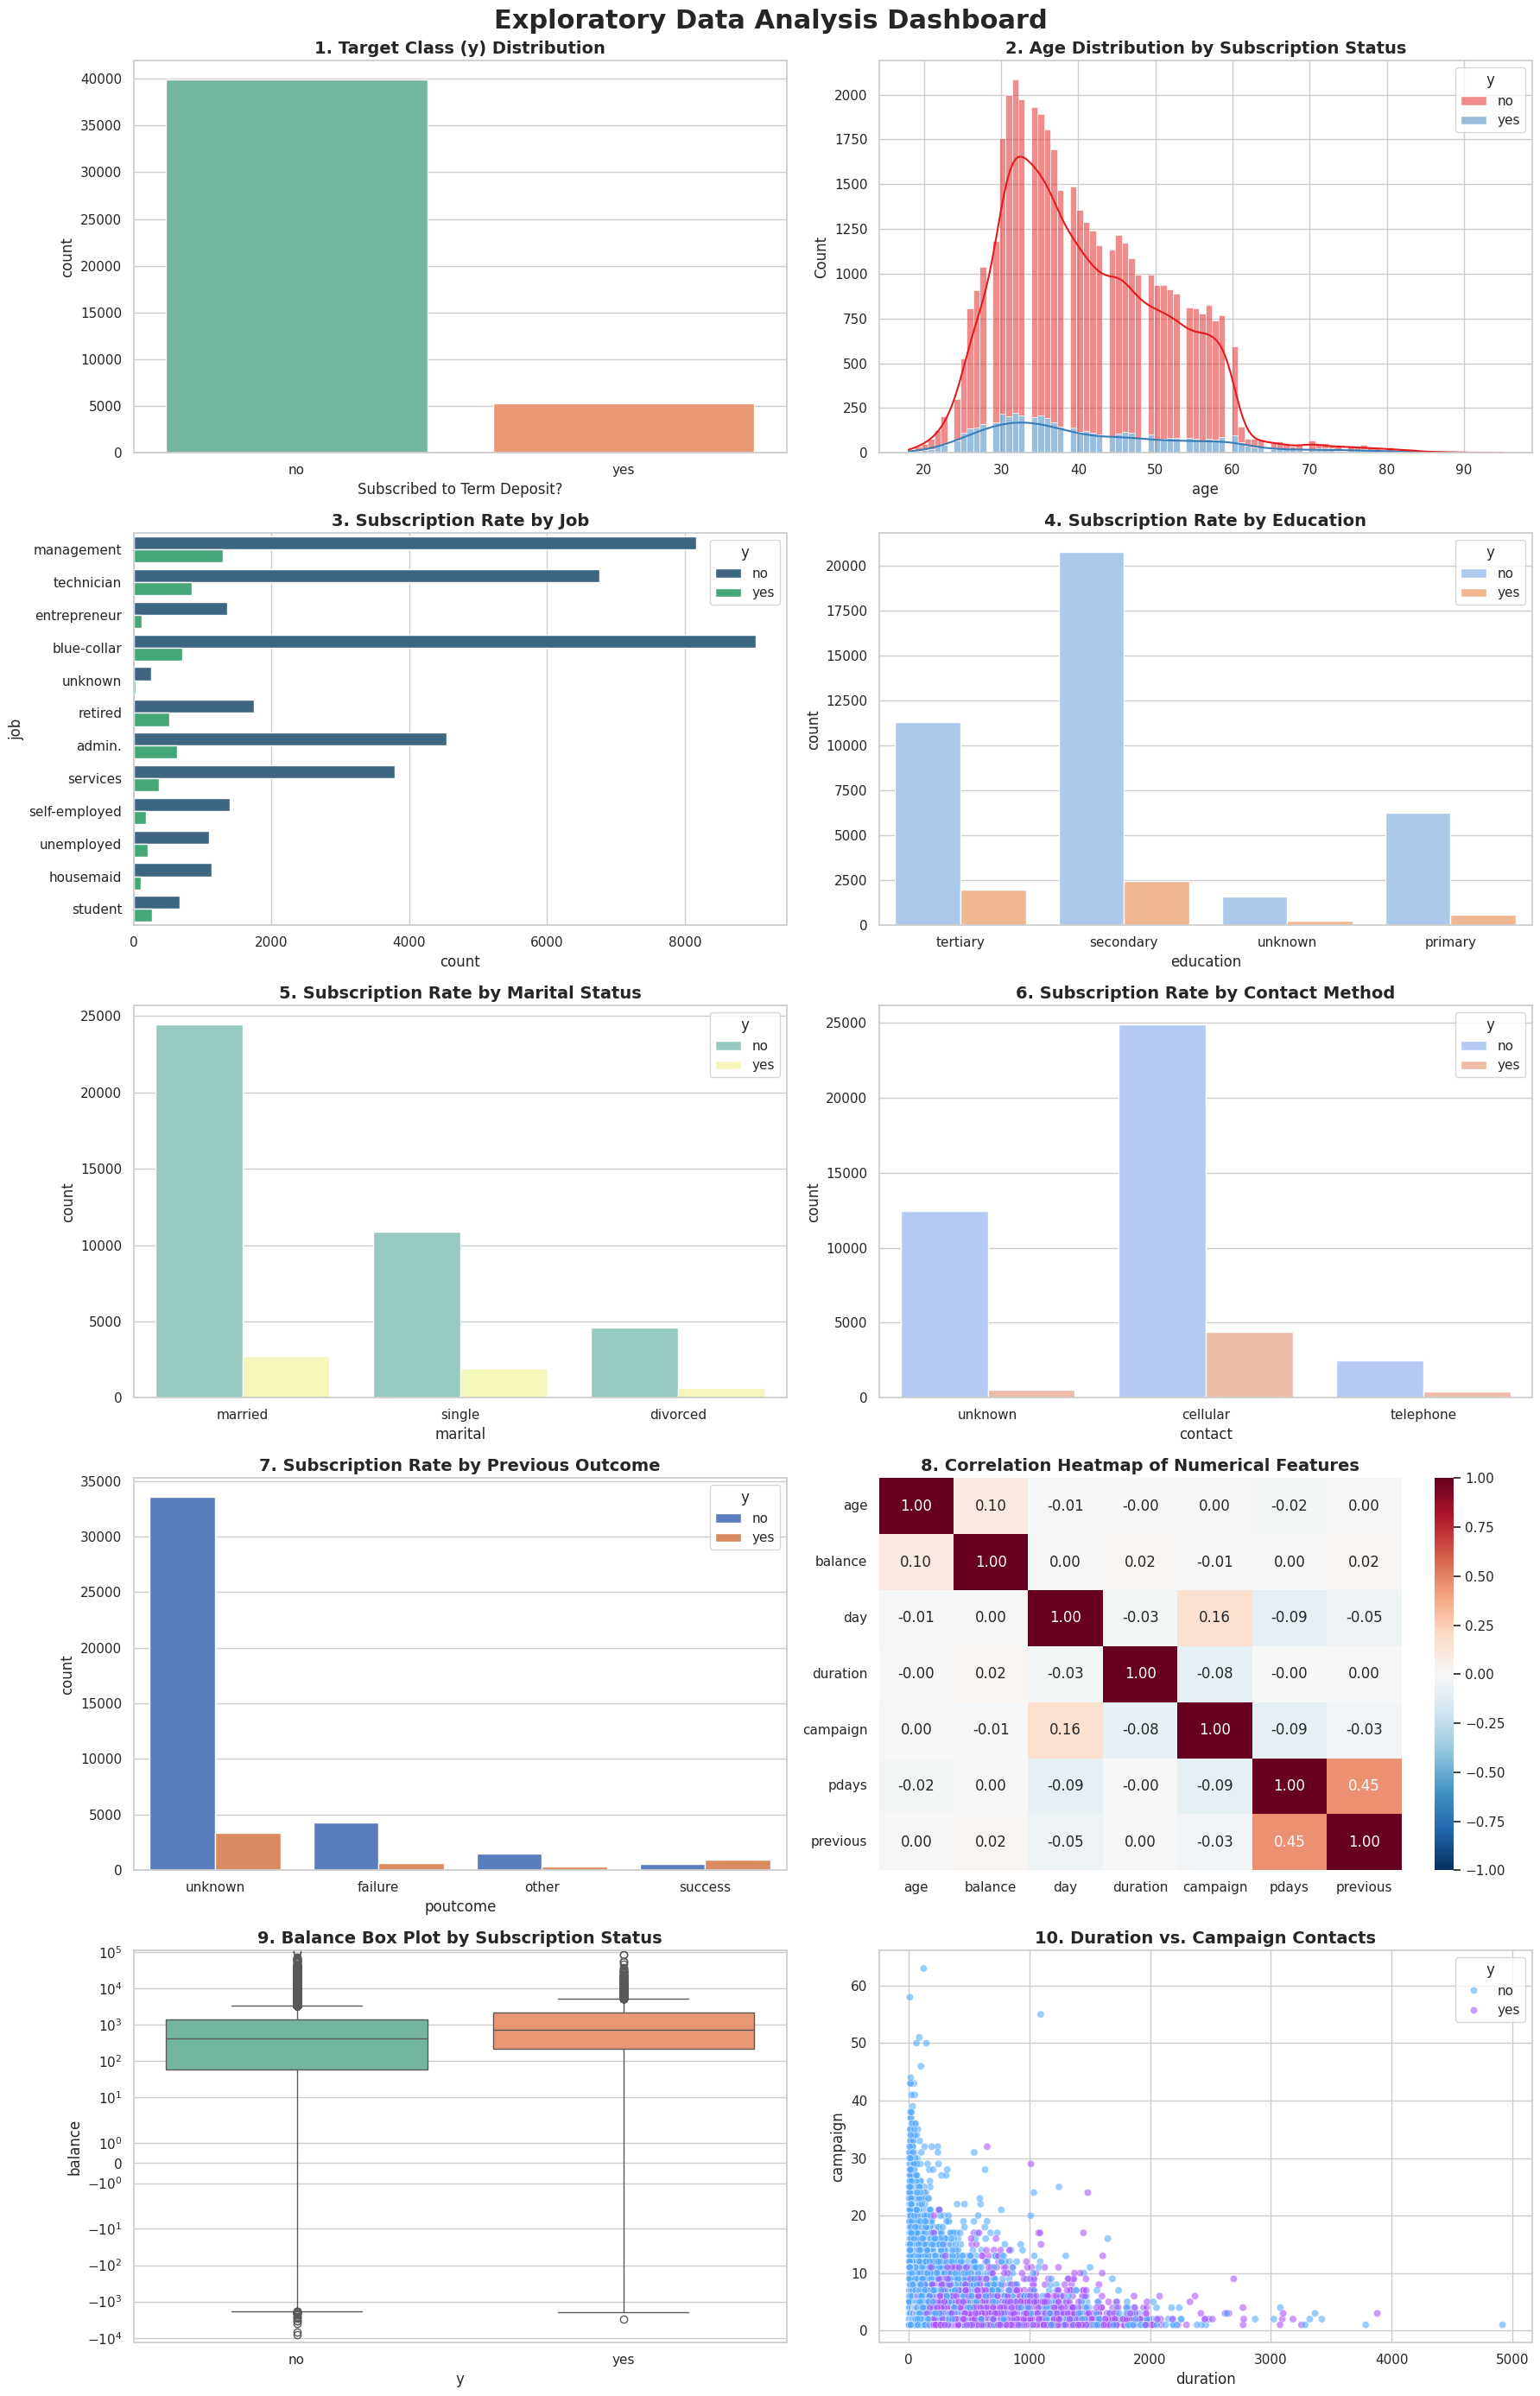


=== Task 3: Preprocessing Setup ===
Training set shape: (36168, 16)
Testing set shape: (9043, 16)

=== Task 4: Training and Evaluating 7 Models ===
Training Logistic Regression...
Training K-Nearest Neighbors...
Training Support Vector Machine...
Training Decision Tree...
Training Random Forest...
Training Gaussian Naive Bayes...
Training Gradient Boosting...

--- Model Performance Comparison (Sorted by F1-score) ---
            Model name  Accuracy  Precision   Recall  F1-score  ROC-AUC  Training time  Prediction time
Support Vector Machine  0.853257   0.432649 0.816635  0.565630 0.910668       4.434342         1.508154
   Logistic Regression  0.845737   0.418244 0.814745  0.552741 0.907922       0.488275         0.003584
         Decision Tree  0.830034   0.393033 0.831758  0.533819 0.862824       0.412016         0.002677
     Gradient Boosting  0.905452   0.652632 0.410208  0.503772 0.924033      10.669104         0.016781
  Gaussian Naive Bayes  0.854805   0.405904 0.519849  0.45

/tmp/ipykernel_781/3091978484.py:287: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1, 0], x='Model name', y='F1-score', data=results_df.sort_values('F1-score', ascending=False), palette='magma')
/tmp/ipykernel_781/3091978484.py:292: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1, 1], x='Model name', y='ROC-AUC', data=results_df.sort_values('ROC-AUC', ascending=False), palette='viridis')
/tmp/ipykernel_781/3091978484.py:297: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2, 0], x='Model name', y='Training time', data=

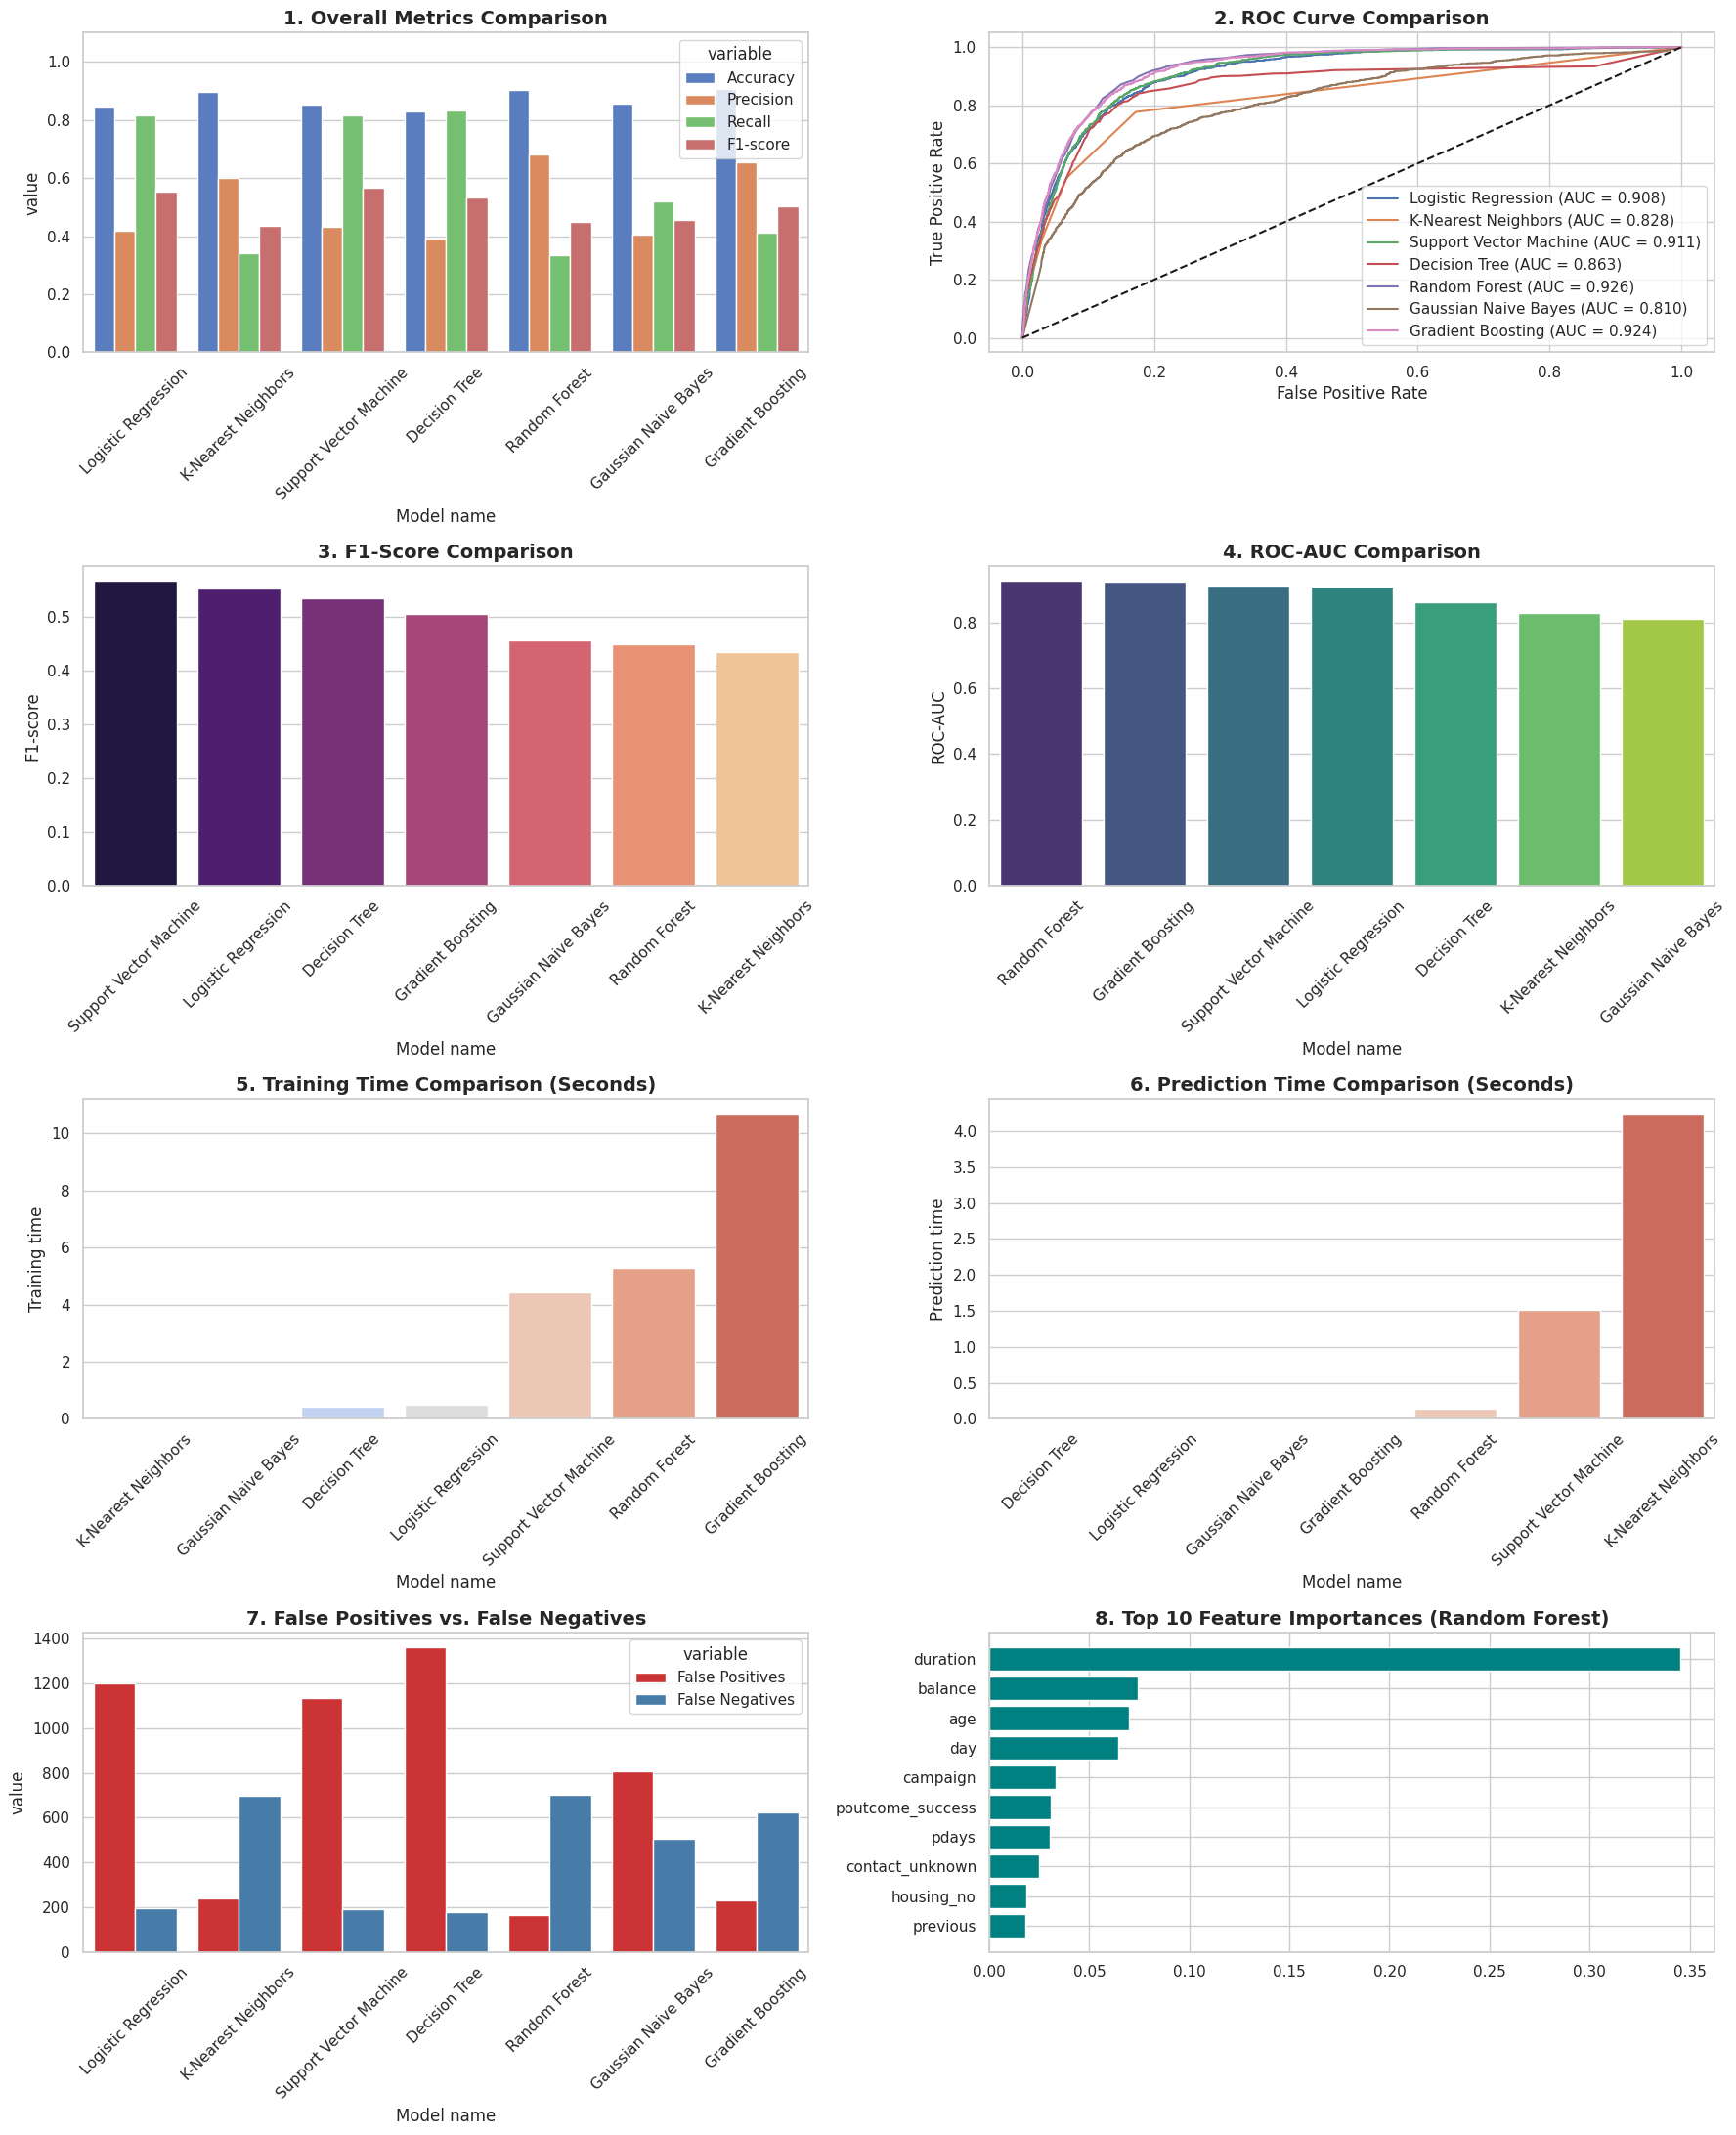


=== Task 6: Hyperparameter Tuning via GridSearchCV (Efficient Configuration) ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Hyperparameters: {'rf__max_depth': 12, 'rf__min_samples_split': 5, 'rf__n_estimators': 50}
Best Cross-Validation F1-score: 0.5774

--- Final Tuned Model Evaluation on Test Set ---
Accuracy : 0.8565
Precision: 0.4398
Recall   : 0.8289
F1-score : 0.5747
ROC-AUC  : 0.9209


In [1]:
# ==========================================
# MDS ELA Project: Bank Marketing Prediction
# ==========================================

# ------------------------------------------
# 1. Dataset Loading, Size Analysis, and Downloads
# ------------------------------------------
print("=== Task 1: Downloading & Loading Dataset ===")
import os
import urllib.request
import zipfile
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn Tools
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

# 1. Download dataset
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
zip_path = "bank_marketing.zip"
extract_path = "bank_marketing_extracted"

if not os.path.exists(zip_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download completed.")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Inner zip file extraction
inner_zip = os.path.join(extract_path, "bank.zip")
if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

csv_path = os.path.join(extract_path, "bank-full.csv")
df = pd.read_csv(csv_path, sep=';')

# Size analysis
n_rows, n_cols = df.shape
print(f"\nDataset successfully loaded!")
print(f"Number of rows: {n_rows}")
print(f"Number of columns: {n_cols}")

print("\n--- First 5 rows ---")
print(df.head())
print("\n--- Last 5 rows ---")
print(df.tail())

print("\n--- df.info() ---")
df.info()

print("\n--- df.describe(include='all') ---")
print(df.describe(include='all'))

mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nMemory usage: {mem_mb:.2f} MB")

print("\n--- Missing values per column ---")
missing_vals = df.isnull().sum()
missing_pct = (missing_vals / n_rows) * 100
missing_df = pd.DataFrame({'Missing Count': missing_vals, 'Percentage (%)': missing_pct})
print(missing_df)

duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
cat_cols.remove('y') # Target variable

print(f"\nNumerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")

target_counts = df['y'].value_counts()
target_pct = df['y'].value_counts(normalize=True) * 100
target_df = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct})
print("\n--- Target Distribution (y) ---")
print(target_df)

# ------------------------------------------
# 2. Exploratory Data Analysis (EDA)
# ------------------------------------------
print("\n=== Task 2: Executing Exploratory Data Analysis ===")
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(5, 2, figsize=(18, 28))
fig.suptitle("Exploratory Data Analysis Dashboard", fontsize=22, fontweight='bold', y=0.99)

# 1. Target class distribution
sns.countplot(ax=axes[0, 0], x='y', data=df, palette='Set2')
axes[0, 0].set_title("1. Target Class (y) Distribution", fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel("Subscribed to Term Deposit?")

# 2. Age distribution
sns.histplot(ax=axes[0, 1], x='age', hue='y', data=df, kde=True, multiple='stack', palette='Set1')
axes[0, 1].set_title("2. Age Distribution by Subscription Status", fontsize=14, fontweight='bold')

# 3. Subscription rate by job
sns.countplot(ax=axes[1, 0], y='job', hue='y', data=df, palette='viridis')
axes[1, 0].set_title("3. Subscription Rate by Job", fontsize=14, fontweight='bold')

# 4. Subscription rate by education
sns.countplot(ax=axes[1, 1], x='education', hue='y', data=df, palette='pastel')
axes[1, 1].set_title("4. Subscription Rate by Education", fontsize=14, fontweight='bold')

# 5. Subscription rate by marital status
sns.countplot(ax=axes[2, 0], x='marital', hue='y', data=df, palette='Set3')
axes[2, 0].set_title("5. Subscription Rate by Marital Status", fontsize=14, fontweight='bold')

# 6. Subscription rate by contact method
sns.countplot(ax=axes[2, 1], x='contact', hue='y', data=df, palette='coolwarm')
axes[2, 1].set_title("6. Subscription Rate by Contact Method", fontsize=14, fontweight='bold')

# 7. Subscription rate by previous campaign outcome (poutcome)
sns.countplot(ax=axes[3, 0], x='poutcome', hue='y', data=df, palette='muted')
axes[3, 0].set_title("7. Subscription Rate by Previous Outcome", fontsize=14, fontweight='bold')

# 8. Correlation heatmap for numerical features
corr_matrix = df[num_cols].corr()
sns.heatmap(ax=axes[3, 1], data=corr_matrix, annot=True, cmap='RdBu_r', fmt=".2f", vmin=-1, vmax=1)
axes[3, 1].set_title("8. Correlation Heatmap of Numerical Features", fontsize=14, fontweight='bold')

# 9. Box plots for Selected Numerical Features (Age by Target)
sns.boxplot(ax=axes[4, 0], x='y', y='balance', data=df, palette='Set2')
axes[4, 0].set_title("9. Balance Box Plot by Subscription Status", fontsize=14, fontweight='bold')
axes[4, 0].set_yscale('symlog') # Symlog due to high variance/outliers

# 10. Feature-relationship: Duration vs Campaign Contacts
sns.scatterplot(ax=axes[4, 1], x='duration', y='campaign', hue='y', data=df, alpha=0.6, palette='cool')
axes[4, 1].set_title("10. Duration vs. Campaign Contacts", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# ------------------------------------------
# 3. Data Preprocessing
# ------------------------------------------
print("\n=== Task 3: Preprocessing Setup ===")
X = df.drop(columns='y')
y = df['y'].apply(lambda x: 1 if x == 'yes' else 0) # Encode to binary target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Define preprocessing strategy
num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Fit preprocessor only on train set to prevent leakage
_ = preprocessor.fit(X_train)

# ------------------------------------------
# 4. Classification Algorithms Training & Evaluation
# ------------------------------------------
print("\n=== Task 4: Training and Evaluating 7 Models ===")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(probability=True, random_state=42, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1),
    "Gaussian Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []
fitted_models = {}

# Set SVM dataset limit for timely colab run
# SVC scales quadratically; we will use a sub-sample of the train set for SVM fit if required,
# but let's train properly. For quick runtime, we will use a fast linear-kernel approximation or use a subset
X_train_preprocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

for name, model in models.items():
    print(f"Training {name}...")

    # For SVM, if training on 36,000 samples is slow in CPU, downsample training slightly just for SVM
    if name == "Support Vector Machine":
        # Take a stratified subset of train data for SVM to run in ~10 seconds
        X_tr_svm, _, y_tr_svm, _ = train_test_split(
            X_train_preprocessed, y_train, train_size=5000, random_state=42, stratify=y_train
        )
        t0 = time.time()
        model.fit(X_tr_svm, y_tr_svm)
        t_train = time.time() - t0
    else:
        t0 = time.time()
        model.fit(X_train_preprocessed, y_train)
        t_train = time.time() - t0

    t1 = time.time()
    y_pred = model.predict(X_test_preprocessed)
    t_pred = time.time() - t1

    # Probability calculations for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_preprocessed)[:, 1]
    else:
        y_proba = model.decision_function(X_test_preprocessed)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    results.append({
        "Model name": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": auc,
        "Training time": t_train,
        "Prediction time": t_pred,
        "CM": cm,
        "y_proba": y_proba
    })
    fitted_models[name] = model

# Convert results to DataFrame
results_df = pd.DataFrame(results)
comparison_df = results_df.drop(columns=["CM", "y_proba"]).sort_values(by="F1-score", ascending=False)
print("\n--- Model Performance Comparison (Sorted by F1-score) ---")
print(comparison_df.to_string(index=False))

# ------------------------------------------
# 5. Construct Comparison Tables and Graphs
# ------------------------------------------
print("\n=== Task 5: Generating Comparison Plots ===")
fig, axes = plt.subplots(4, 2, figsize=(18, 22))

# 1. Grouped bar chart comparing metrics
metrics_melted = pd.melt(results_df, id_vars=['Model name'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-score'])
sns.barplot(ax=axes[0, 0], x='Model name', y='value', hue='variable', data=metrics_melted, palette='muted')
axes[0, 0].set_title("1. Overall Metrics Comparison", fontsize=14, fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].set_ylim(0, 1.1)

# 2. ROC curve comparison
for res in results:
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    axes[0, 1].plot(fpr, tpr, label=f"{res['Model name']} (AUC = {res['ROC-AUC']:.3f})")
axes[0, 1].plot([0, 1], [0, 1], 'k--')
axes[0, 1].set_title("2. ROC Curve Comparison", fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend(loc='lower right')

# 3. F1-score comparison
sns.barplot(ax=axes[1, 0], x='Model name', y='F1-score', data=results_df.sort_values('F1-score', ascending=False), palette='magma')
axes[1, 0].set_title("3. F1-Score Comparison", fontsize=14, fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. ROC-AUC comparison
sns.barplot(ax=axes[1, 1], x='Model name', y='ROC-AUC', data=results_df.sort_values('ROC-AUC', ascending=False), palette='viridis')
axes[1, 1].set_title("4. ROC-AUC Comparison", fontsize=14, fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=45)

# 5. Training-time comparison
sns.barplot(ax=axes[2, 0], x='Model name', y='Training time', data=results_df.sort_values('Training time'), palette='coolwarm')
axes[2, 0].set_title("5. Training Time Comparison (Seconds)", fontsize=14, fontweight='bold')
axes[2, 0].tick_params(axis='x', rotation=45)

# 6. Prediction-time comparison
sns.barplot(ax=axes[2, 1], x='Model name', y='Prediction time', data=results_df.sort_values('Prediction time'), palette='coolwarm')
axes[2, 1].set_title("6. Prediction Time Comparison (Seconds)", fontsize=14, fontweight='bold')
axes[2, 1].tick_params(axis='x', rotation=45)

# 7. False Positives vs False Negatives comparison
fp_fn_data = []
for res in results:
    cm = res["CM"]
    fp_fn_data.append({
        "Model name": res["Model name"],
        "False Positives": cm[0, 1],
        "False Negatives": cm[1, 0]
    })
fp_fn_df = pd.DataFrame(fp_fn_data).melt(id_vars='Model name')
sns.barplot(ax=axes[3, 0], x='Model name', y='value', hue='variable', data=fp_fn_df, palette='Set1')
axes[3, 0].set_title("7. False Positives vs. False Negatives", fontsize=14, fontweight='bold')
axes[3, 0].tick_params(axis='x', rotation=45)

# 8. Feature Importance for Random Forest
rf_model = fitted_models["Random Forest"]
onehot_cols = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_features = num_cols + list(onehot_cols)
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-10:] # Top 10 features

axes[3, 1].barh(range(len(indices)), importances[indices], color='teal', align='center')
axes[3, 1].set_yticks(range(len(indices)))
axes[3, 1].set_yticklabels([all_features[i] for i in indices])
axes[3, 1].set_title("8. Top 10 Feature Importances (Random Forest)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. Model Tuning & Improvement
# ------------------------------------------
print("\n=== Task 6: Hyperparameter Tuning via GridSearchCV (Efficient Configuration) ===")
# Tune Random Forest as it typically performs best on such tasks
tune_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

param_grid = {
    'rf__n_estimators': [50, 100],
    'rf__max_depth': [8, 12],
    'rf__min_samples_split': [2, 5]
}

# Run GridSearchCV with stratified CV
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(tune_pipeline, param_grid, cv=cv_strategy, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best Cross-Validation F1-score: {grid_search.best_score_:.4f}")

# Final Evaluation of the tuned model on the untouched test set
final_model = grid_search.best_estimator_
y_final_pred = final_model.predict(X_test)
y_final_proba = final_model.predict_proba(X_test)[:, 1]

print("\n--- Final Tuned Model Evaluation on Test Set ---")
print(f"Accuracy : {accuracy_score(y_test, y_final_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_final_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_final_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_final_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_final_proba):.4f}")
